# Executive Decision Report - Final Analytical Notebook
**Data Analytics & Business Intelligence Internship - Capstone**

This notebook is the complete, reproducible analytics portfolio behind the *Executive Decision Report* (PDF deck). It runs end to end:

1. **Ingest & profile** the raw omnichannel retail order data (12,400 rows)
2. **Clean & preprocess** with Pandas (duplicates, types, missing values, outliers) and engineer features
3. **Measure** performance and identify the **key revenue drivers**
4. **Diagnose risk areas** and test three business hypotheses statistically
5. **Quantify three strategic recommendations** - ROI projections (3 scenarios) and implementation timeline
6. **Export** `clean_dataset.csv` and `metrics.json` (the single source of truth for every number in the deck)

> **Data note.** The dataset is a *simulated*, seeded retail dataset (`generate_raw_data.py`) built to mirror a real omnichannel retailer, with realistic data-quality issues injected. All financial figures are in **USD** and are on a **booked basis** (before refunds); returns are analysed separately as a leakage item. ROI figures are *model-based projections* driven by the explicit assumptions in Section 6.

## 1. Setup

In [1]:
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from scipy import stats
warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.max_columns", 30)

# --- chart style (one-hue bars; orange reserved for "needs attention") ---
BLUE, ORANGE, GRAY, INK, INK2, GRID = "#2a78d6", "#eb6834", "#c3c2b7", "#0b0b0b", "#52514e", "#e1e0d9"
for f in ["LiberationSans-Regular.ttf", "LiberationSans-Bold.ttf"]:
    font_manager.fontManager.addfont(f"/usr/share/fonts/truetype/liberation/{f}")
plt.rcParams.update({
    "font.family": "Liberation Sans", "font.size": 10, "axes.edgecolor": GRID,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.titlecolor": INK, "figure.dpi": 110, "figure.facecolor": "white"})

def bars(ax, labels, vals, colors=None, fmt="{:,.0f}", horizontal=False, title=None, ylabel=None):
    colors = colors or [BLUE] * len(vals)
    if horizontal:
        b = ax.barh(labels, vals, color=colors, height=0.62); ax.grid(axis="y", visible=False)
        ax.invert_yaxis()
        for r, v in zip(b, vals):
            ax.text(v + (max(vals) - min(0, min(vals))) * 0.01 if v >= 0 else v - (max(vals) - min(0, min(vals))) * 0.01,
                    r.get_y() + r.get_height() / 2, fmt.format(v), va="center",
                    ha="left" if v >= 0 else "right", color=INK, fontsize=9)
    else:
        b = ax.bar(labels, vals, color=colors, width=0.62); ax.grid(axis="x", visible=False)
        rng_ = max(vals) - min(0, min(vals))
        for r, v in zip(b, vals):
            ax.text(r.get_x() + r.get_width() / 2, v + (rng_ * 0.015 if v >= 0 else -rng_ * 0.015), fmt.format(v),
                    ha="center", va="bottom" if v >= 0 else "top", color=INK, fontsize=9)
    ax.axhline(0, color=INK2, lw=0.8) if not horizontal else ax.axvline(0, color=INK2, lw=0.8)
    if title: ax.set_title(title, loc="left")
    if ylabel: ax.set_ylabel(ylabel)
    return b

## 2. Ingest & Profile the Raw Data

In [2]:
raw = pd.read_csv("raw_sales_data.csv")
print("Shape:", raw.shape)
display(raw.head())
print(raw.dtypes.to_string())

Shape: (12400, 16)


,order_id,order_date,customer_id,segment,region,category,sub_category,channel,quantity,unit_price,discount,unit_cost,sales,profit,ship_days,returned
0,ORD-010839,14/11/2025,C1878,Consumer,NaN,Technology,Phones,Online,1.00,420.93,0.05,316.61,399.89,67.28,5.00,Yes
1,ORD-007488,2025-02-01,C0863,Corporate,South,Office Supplies,Storage,Retail Store,5.00,51.56,0.25,31.41,193.34,36.29,4.00,No
2,ORD-006891,19/12/2024,C0524,corporate,North,Technology,Laptops,Retail Store,3.00,881.08,0.20,665.45,2114.6,118.24,6.00,No
3,ORD-000204,2023-02-01,C0534,Corporate,West,Furniture,Furnishings,Marketplace,3.00,75.18,0.40,35.82,135.32,10.27,7.00,No
4,ORD-009765,2025-08-12,C2034,Consumer,NaN,Furniture,Bookcases,Online,1.00,337.58,0.15,216.69,286.94,58.78,5.00,No


order_id            str
order_date          str
customer_id         str
segment             str
region              str
category            str
sub_category        str
channel             str
quantity        float64
unit_price      float64
discount        float64
unit_cost       float64
sales               str
profit              str
ship_days       float64
returned            str


,missing,missing_%
segment,188,1.52
region,247,1.99
category,61,0.49
quantity,122,0.98
discount,369,2.98
ship_days,306,2.47


Exact duplicate rows: 400
Inconsistent labels - region: [' Central ', ' EAST ', ' East ', ' NORTH ', ' North ', ' SOUTH ', ' South ', ' WEST ', ' West ', ' central ', ' east ', ' north ', ' south ', ' west ', 'CENTRAL', 'Central', 'EAST', 'East', 'NORTH', 'North', 'SOUTH', 'South', 'WEST', 'West', 'central', 'east', 'north', 'south', 'west']
sales stored as text ($...): 1864 | profit stored as text: 1856


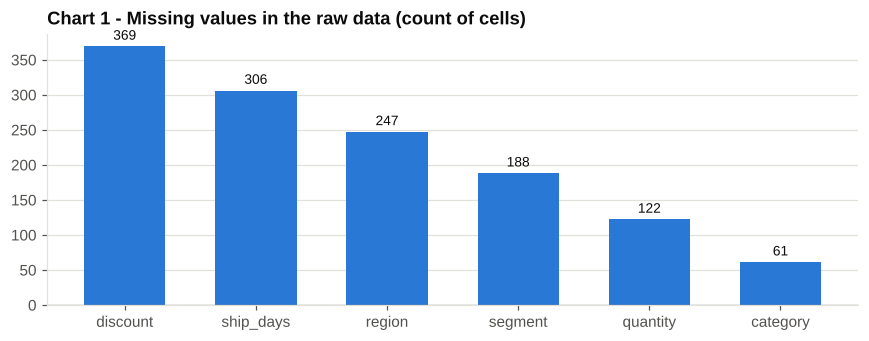

In [3]:
missing_before = raw.isna().sum()
profile = pd.DataFrame({"missing": missing_before, "missing_%": (missing_before / len(raw) * 100).round(2)})
display(profile[profile.missing > 0])
print("Exact duplicate rows:", raw.duplicated().sum())
print("Inconsistent labels - region:", sorted(raw.region.dropna().unique()))
print("sales stored as text ($...):", raw.sales.astype(str).str.startswith("$").sum(),
      "| profit stored as text:", raw.profit.astype(str).str.startswith("$").sum())

fig, ax = plt.subplots(figsize=(8, 3.2))
mb = missing_before[missing_before > 0].sort_values(ascending=False)
bars(ax, mb.index, mb.values, title="Chart 1 - Missing values in the raw data (count of cells)")
plt.tight_layout(); plt.show()

## 3. Cleaning & Preprocessing
Every step is logged so the before/after impact can be audited. Order matters: the discount and quantity are recovered from the order's own arithmetic *before* any outlier correction.

In [4]:
FEE = {"Retail Store": 0.00, "Online": 0.04, "Marketplace": 0.13}      # channel fee as % of sales
LEVELS = np.array([0, .05, .10, .15, .20, .25, .30, .35, .40, .50])    # valid discount tiers
MAX_QTY = 20                                                           # business rule: >20 units/line = keying error
log = {"rows_raw": len(raw)}

df = raw.copy()

# 3.1 duplicates ---------------------------------------------------------------------
log["duplicates_removed"] = int(df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)

# 3.2 data types ---------------------------------------------------------------------
for c in ["sales", "profit"]:
    log[f"{c}_text_to_numeric"] = int(df[c].astype(str).str.startswith("$").sum())
    df[c] = pd.to_numeric(df[c].astype(str).str.replace(r"[$,]", "", regex=True))

def parse_date(s):
    for fmt in ("%Y-%m-%d", "%d/%m/%Y", "%b %d, %Y"):
        try: return pd.to_datetime(s, format=fmt)
        except ValueError: continue
    return pd.NaT
fmt_counts = {"iso": df.order_date.str.match(r"^\d{4}-").sum(), "dd/mm/yyyy": df.order_date.str.contains("/").sum(),
              "Mon dd, yyyy": df.order_date.str.contains(",").sum()}
log["date_formats_standardised"] = {k: int(v) for k, v in fmt_counts.items()}
df["order_date"] = df.order_date.map(parse_date)
assert df.order_date.notna().all()

df["returned"] = df.returned.str.strip().str.upper().str[0].map({"Y": True, "N": False})

# 3.3 inconsistent text labels -----------------------------------------------------------
before = {c: df[c].nunique() for c in ["region", "segment", "category"]}
for c in ["region", "segment", "category"]:
    df[c] = df[c].str.strip().str.title()
log["label_variants_collapsed"] = {c: f"{before[c]} -> {df[c].nunique()}" for c in before}

# 3.4 missing values -------------------------------------------------------------------
log["missing_cells_before"] = int(df.isna().sum().sum())
#   category <- deterministic from sub_category
cat_map = df.dropna(subset=["category"]).drop_duplicates("sub_category").set_index("sub_category").category
df["category"] = df.category.fillna(df.sub_category.map(cat_map))
#   region / segment <- the customer's own most common value
for c in ["region", "segment"]:
    mode = df.dropna(subset=[c]).groupby("customer_id")[c].agg(lambda s: s.mode().iat[0])
    df[c] = df[c].fillna(df.customer_id.map(mode))
    log[f"{c}_filled_global_mode"] = int(df[c].isna().sum())      # single-order customers: no other row to learn from
    df[c] = df[c].fillna(df[c].mode().iat[0])
#   discount <- recovered from the order arithmetic: 1 - sales / (qty * unit_price), snapped to a valid tier
m = df.discount.isna() & df.quantity.notna()
implied = 1 - df.loc[m, "sales"] / (df.loc[m, "quantity"] * df.loc[m, "unit_price"])
df.loc[m, "discount"] = LEVELS[np.abs(implied.values[:, None] - LEVELS[None, :]).argmin(axis=1)]
#   quantity <- sales / (unit_price * (1 - discount))
m = df.quantity.isna() & df.discount.notna()
df.loc[m, "quantity"] = (df.loc[m, "sales"] / (df.loc[m, "unit_price"] * (1 - df.loc[m, "discount"]))).round()
log["rows_dropped_unrecoverable"] = int(df[["discount", "quantity"]].isna().any(axis=1).sum())
df = df.dropna(subset=["discount", "quantity"]).copy()
#   ship_days <- median for the order's region (flagged)
df["ship_days_imputed"] = df.ship_days.isna()
df["ship_days"] = df.ship_days.fillna(df.groupby("region").ship_days.transform("median"))
log["ship_days_imputed"] = int(df.ship_days_imputed.sum())

# 3.5 outliers (entry errors) ----------------------------------------------------------
q1, q3 = df.sales.quantile([.25, .75]); iqr = q3 - q1
log["sales_iqr_flagged_(info)"] = int((df.sales > q3 + 3 * iqr).sum())
bad = df.quantity > MAX_QTY
log["quantity_entry_errors_fixed"] = int(bad.sum())
med_qty = df[~bad].groupby("sub_category").quantity.median()
df.loc[bad, "quantity"] = df.loc[bad, "sub_category"].map(med_qty)
df["quantity"] = df.quantity.astype(int)
# recompute money fields from components for the corrected lines
df.loc[bad, "sales"] = (df.quantity * df.unit_price * (1 - df.discount))[bad].round(2)
df.loc[bad, "profit"] = (df.sales * (1 - df.channel.map(FEE)) - df.quantity * df.unit_cost)[bad].round(2)

# 3.6 validation -------------------------------------------------------------------------
expected = df.quantity * df.unit_price * (1 - df.discount)
log["rows_clean"] = len(df)
log["missing_cells_after"] = int(df.drop(columns=[]).isna().sum().sum())
log["sales_arithmetic_consistent_%"] = round(float(((df.sales - expected).abs() / expected < 0.02).mean() * 100), 2)
assert df.isna().sum().sum() == 0 and df.order_id.is_unique
print(json.dumps(log, indent=2, default=str))

{
  "rows_raw": 12400,
  "duplicates_removed": 400,
  "sales_text_to_numeric": 1800,
  "profit_text_to_numeric": 1800,
  "date_formats_standardised": {
    "iso": 8871,
    "dd/mm/yyyy": 1929,
    "Mon dd, yyyy": 1200
  },
  "label_variants_collapsed": {
    "region": "29 -> 5",
    "segment": "9 -> 3",
    "category": "18 -> 3"
  },
  "missing_cells_before": 1260,
  "region_filled_global_mode": 13,
  "segment_filled_global_mode": 7,
  "rows_dropped_unrecoverable": 4,
  "ship_days_imputed": 300,
  "sales_iqr_flagged_(info)": 430,
  "quantity_entry_errors_fixed": 28,
  "rows_clean": 11996,
  "missing_cells_after": 0,
  "sales_arithmetic_consistent_%": 100.0
}


### 3.7 Feature engineering

In [5]:
df["order_year"] = df.order_date.dt.year
df["order_month"] = df.order_date.dt.month
df["order_quarter"] = df.order_date.dt.quarter
df["year_month"] = df.order_date.dt.to_period("M").astype(str)
df["profit_margin"] = df.profit / df.sales
df["discount_band"] = pd.cut(df.discount, [-0.01, 0, 0.10, 0.20, 0.30, 1],
                             labels=["0%", "1-10%", "11-20%", "21-30%", ">30%"])
df["is_late"] = df.ship_days > 5
df["is_loss_order"] = df.profit < 0
n_ord = df.groupby("customer_id").order_id.transform("count")
df["customer_type"] = np.where(n_ord > 1, "Repeat", "One-time")
df["channel_fee"] = df.channel.map(FEE)

df.to_csv("clean_dataset.csv", index=False)
print("clean_dataset.csv exported:", df.shape)
display(df.head())

clean_dataset.csv exported: (11996, 27)


,order_id,order_date,customer_id,segment,region,category,sub_category,channel,quantity,unit_price,discount,unit_cost,sales,profit,ship_days,returned,ship_days_imputed,order_year,order_month,order_quarter,year_month,profit_margin,discount_band,is_late,is_loss_order,customer_type,channel_fee
0,ORD-010839,2025-11-14,C1878,Consumer,South,Technology,Phones,Online,1,420.93,0.05,316.61,399.89,67.28,5.00,True,False,2025,11,4,2025-11,0.17,1-10%,False,False,Repeat,0.04
1,ORD-007488,2025-02-01,C0863,Corporate,South,Office Supplies,Storage,Retail Store,5,51.56,0.25,31.41,193.34,36.29,4.00,False,False,2025,2,1,2025-02,0.19,21-30%,False,False,Repeat,0.00
2,ORD-006891,2024-12-19,C0524,Corporate,North,Technology,Laptops,Retail Store,3,881.08,0.20,665.45,"2,114.60",118.24,6.00,False,False,2024,12,4,2024-12,0.06,11-20%,True,False,Repeat,0.00
3,ORD-000204,2023-02-01,C0534,Corporate,West,Furniture,Furnishings,Marketplace,3,75.18,0.40,35.82,135.32,10.27,7.00,False,False,2023,2,1,2023-02,0.08,>30%,True,False,Repeat,0.13
4,ORD-009765,2025-08-12,C2034,Consumer,West,Furniture,Bookcases,Online,1,337.58,0.15,216.69,286.94,58.78,5.00,False,False,2025,8,3,2025-08,0.20,11-20%,False,False,One-time,0.04


In [6]:
# Before / after summary
ba = pd.DataFrame({
    "Metric": ["Rows", "Missing cells", "Duplicate rows", "Text-formatted money fields", "Date formats", "Region label variants",
               "Quantity entry errors"],
    "Before": [log["rows_raw"], log["missing_cells_before"] + 0, log["duplicates_removed"],
               log["sales_text_to_numeric"] + log["profit_text_to_numeric"], 3, before["region"], log["quantity_entry_errors_fixed"]],
    "After": [log["rows_clean"], 0, 0, 0, 1, df.region.nunique(), 0]})
display(ba)

,Metric,Before,After
0,Rows,12400,11996
1,Missing cells,1260,0
2,Duplicate rows,400,0
3,Text-formatted money fields,3600,0
4,Date formats,3,1
5,Region label variants,29,5
6,Quantity entry errors,28,0


## 4. Performance Snapshot & Key Revenue Drivers

order_year,2023,2024,2025,YoY 2025
revenue,"896,588.03","1,076,643.61","1,400,396.80",30.07
profit,"138,397.72","152,572.32","167,087.95",9.51
margin_%,15.44,14.17,11.93,-15.80
orders,"3,079.00","3,939.00","4,978.00",26.38
customers,524.00,"1,003.00","1,376.00",37.19
aov,291.19,273.33,281.32,2.92
return_rate_%,6.11,7.49,7.37,-1.56
late_%,21.47,23.33,23.10,-0.98


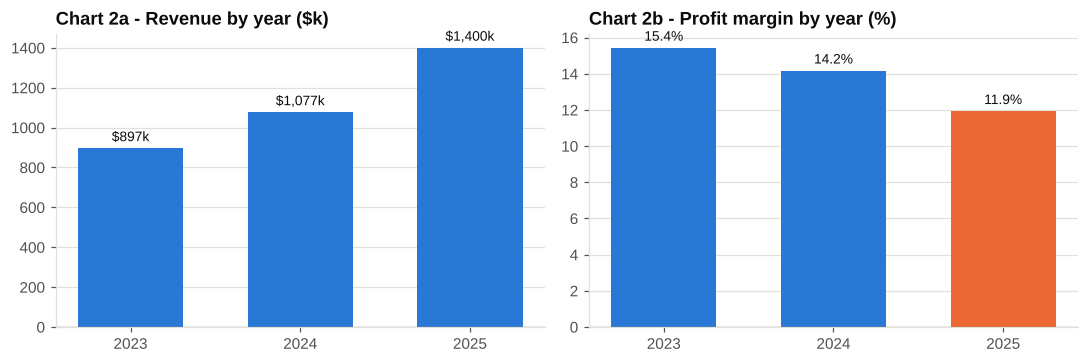

In [7]:
def kpis(d):
    return pd.Series({
        "revenue": d.sales.sum(), "profit": d.profit.sum(), "margin_%": d.profit.sum() / d.sales.sum() * 100,
        "orders": len(d), "customers": d.customer_id.nunique(), "aov": d.sales.mean(),
        "return_rate_%": d.returned.mean() * 100, "late_%": d.is_late.mean() * 100})
by_year = df.groupby("order_year").apply(kpis).T
by_year["YoY 2025"] = (by_year[2025] / by_year[2024] - 1) * 100
display(by_year)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
yr = by_year.drop(columns="YoY 2025")
bars(axes[0], yr.columns.astype(str), yr.loc["revenue"].values / 1e3, fmt="${:,.0f}k", title="Chart 2a - Revenue by year ($k)")
bars(axes[1], yr.columns.astype(str), yr.loc["margin_%"].values, colors=[BLUE, BLUE, ORANGE], fmt="{:.1f}%",
     title="Chart 2b - Profit margin by year (%)")
plt.tight_layout(); plt.show()

,revenue,profit,margin
category,,,
Furniture,"1,293,350.39","157,456.38",12.17
Office Supplies,"432,491.63","152,228.58",35.20
Technology,"1,647,786.42","148,373.03",9.00


,category,sub_category,revenue,profit,margin
11,Technology,Phones,"524,402.42","68,513.21",13.07
1,Furniture,Chairs,"329,377.96","62,204.95",18.89
8,Office Supplies,Storage,"179,023.59","50,207.88",28.05
5,Office Supplies,Binders,"106,516.76","44,715.69",41.98
2,Furniture,Furnishings,"119,903.75","43,722.58",36.46
9,Technology,Accessories,"114,299.82","41,834.60",36.60
10,Technology,Laptops,"800,864.77","33,235.14",4.15
0,Furniture,Bookcases,"348,474.26","26,020.10",7.47
3,Furniture,Tables,"495,594.42","25,508.75",5.15
7,Office Supplies,Paper,"65,809.99","24,311.15",36.94


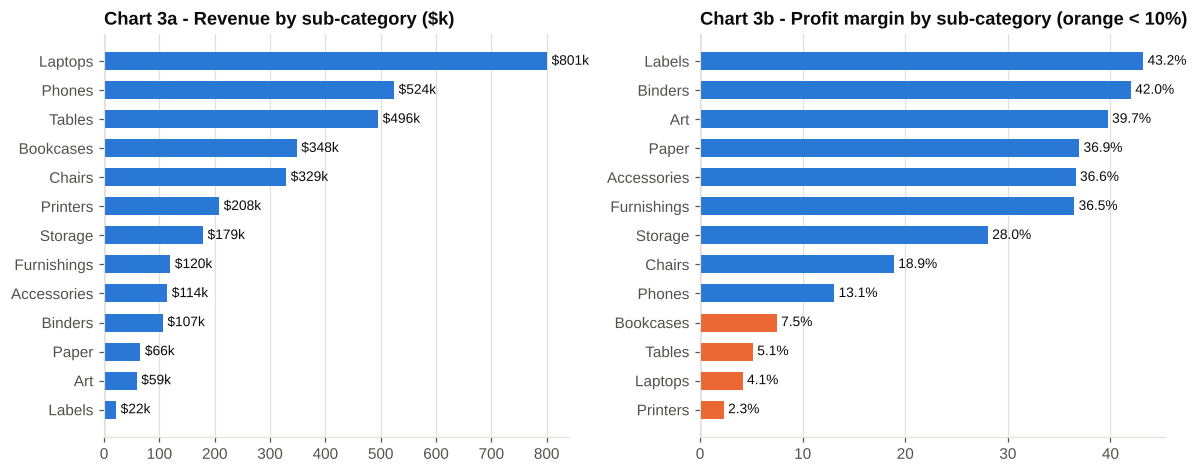

In [8]:
cat = df.groupby("category").agg(revenue=("sales", "sum"), profit=("profit", "sum")).assign(margin=lambda x: x.profit / x.revenue * 100)
sub = df.groupby(["category", "sub_category"]).agg(revenue=("sales", "sum"), profit=("profit", "sum")).assign(
    margin=lambda x: x.profit / x.revenue * 100).reset_index().sort_values("profit", ascending=False)
display(cat); display(sub)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
s1 = sub.sort_values("revenue", ascending=False)
bars(axes[0], s1.sub_category, s1.revenue / 1e3, horizontal=True, fmt="${:,.0f}k", title="Chart 3a - Revenue by sub-category ($k)")
s2 = sub.sort_values("margin", ascending=False)
bars(axes[1], s2.sub_category, s2.margin, colors=[ORANGE if v < 10 else BLUE for v in s2.margin], horizontal=True,
     fmt="{:.1f}%", title="Chart 3b - Profit margin by sub-category (orange < 10%)")
plt.tight_layout(); plt.show()

,revenue,profit,late,margin
region,,,,
West,"1,083,664.17","145,266.73",0.12,13.41
North,"838,042.45","115,559.55",0.19,13.79
South,"617,347.85","85,833.27",0.26,13.90
East,"536,192.42","71,004.62",0.30,13.24
Central,"298,381.55","40,393.82",0.58,13.54


,revenue,profit,margin
channel,,,
Online,"1,530,616.08","229,616.18",15.00
Retail Store,"1,158,941.80","245,878.61",21.22
Marketplace,"684,070.56","-17,436.80",-2.55


channel,Marketplace,Online,Retail Store
order_year,,,
2023,12.41,44.25,43.34
2024,18.90,46.20,34.90
2025,26.37,45.45,28.18


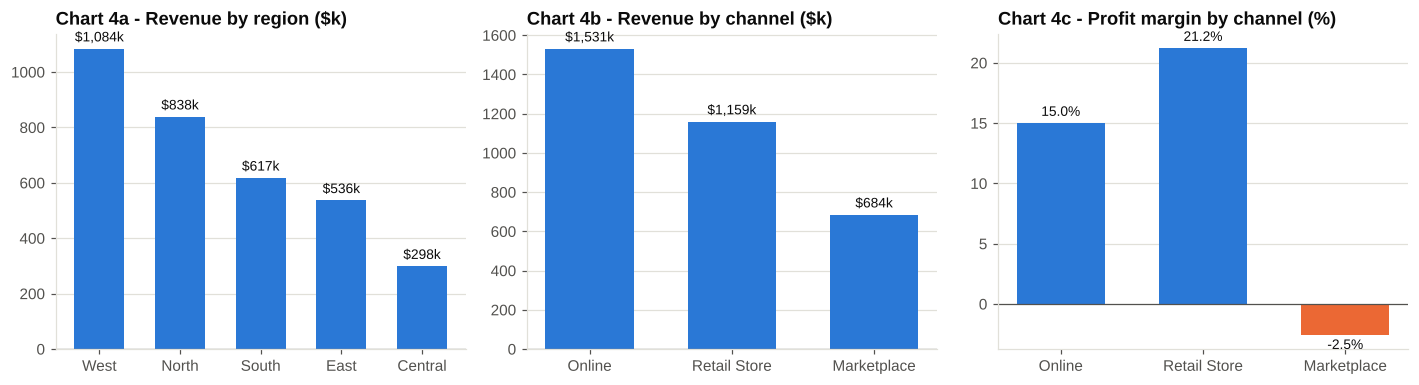

In [9]:
reg = df.groupby("region").agg(revenue=("sales", "sum"), profit=("profit", "sum"), late=("is_late", "mean")).assign(
    margin=lambda x: x.profit / x.revenue * 100).sort_values("revenue", ascending=False)
chn = df.groupby("channel").agg(revenue=("sales", "sum"), profit=("profit", "sum")).assign(
    margin=lambda x: x.profit / x.revenue * 100).sort_values("revenue", ascending=False)
mix = df.groupby(["order_year", "channel"]).sales.sum().unstack()
mix_pct = mix.div(mix.sum(axis=1), axis=0) * 100
display(reg); display(chn); display(mix_pct)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
bars(axes[0], reg.index, reg.revenue / 1e3, fmt="${:,.0f}k", title="Chart 4a - Revenue by region ($k)")
bars(axes[1], chn.index, chn.revenue / 1e3, fmt="${:,.0f}k", title="Chart 4b - Revenue by channel ($k)")
bars(axes[2], chn.index, chn.margin, colors=[ORANGE if v < 5 else BLUE for v in chn.margin], fmt="{:.1f}%",
     title="Chart 4c - Profit margin by channel (%)")
plt.tight_layout(); plt.show()

{'customers': 2116, 'top20_revenue_share_%': np.float64(66.08316711961321), 'top20_profit_share_%': np.float64(65.44344527207134)}
Retention 2023->24: 54.4% | 2024->25: 49.7% | repeat-customer share: 71.4%
customer_type
One-time   305.56
Repeat     279.93
Name: sales, dtype: float64


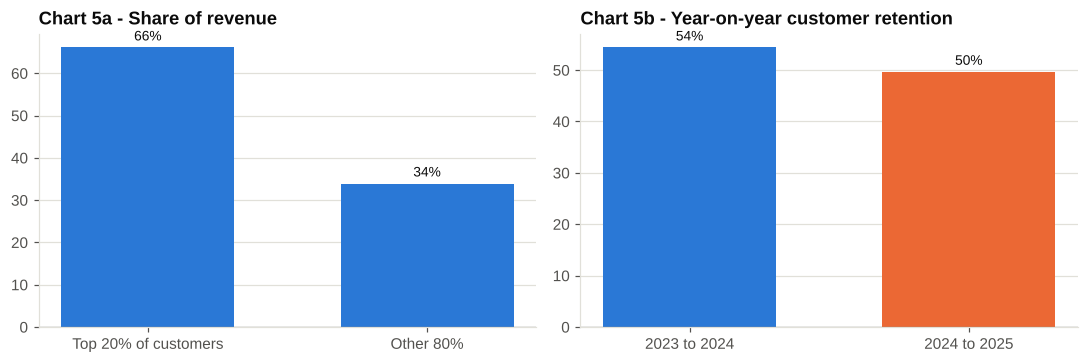

In [10]:
cust = df.groupby("customer_id").agg(revenue=("sales", "sum"), profit=("profit", "sum"), orders=("order_id", "count"))
cust = cust.sort_values("revenue", ascending=False)
top20 = cust.head(int(len(cust) * 0.2))
conc = {"customers": len(cust), "top20_revenue_share_%": top20.revenue.sum() / cust.revenue.sum() * 100,
        "top20_profit_share_%": top20.profit.sum() / cust.profit.sum() * 100}
act = {y: set(df.loc[df.order_year == y, "customer_id"]) for y in (2023, 2024, 2025)}
ret_24_25 = len(act[2024] & act[2025]) / len(act[2024]) * 100
ret_23_24 = len(act[2023] & act[2024]) / len(act[2023]) * 100
rep_rate = (cust.orders > 1).mean() * 100
aov_ct = df.groupby("customer_type").sales.mean()
print(conc); print(f"Retention 2023->24: {ret_23_24:.1f}% | 2024->25: {ret_24_25:.1f}% | repeat-customer share: {rep_rate:.1f}%")
print(aov_ct)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
bars(axes[0], ["Top 20% of customers", "Other 80%"], [conc["top20_revenue_share_%"], 100 - conc["top20_revenue_share_%"]],
     fmt="{:.0f}%", title="Chart 5a - Share of revenue")
bars(axes[1], ["2023 to 2024", "2024 to 2025"], [ret_23_24, ret_24_25], colors=[BLUE, ORANGE], fmt="{:.0f}%",
     title="Chart 5b - Year-on-year customer retention")
plt.tight_layout(); plt.show()

## 5. Risk Areas & Hypothesis Tests
**H1** - Orders discounted by more than 20% earn a lower profit margin than orders at 20% or less.
**H2** - Marketplace orders earn a lower profit margin than non-marketplace orders.
**H3** - Late shipments (> 5 days) are returned more often than on-time shipments.

,orders,revenue,profit,loss_orders,margin
discount_band,,,,,
0%,3229,"1,009,126.00","290,054.22",0.12,28.74
1-10%,2325,"683,633.30","152,955.79",0.82,22.37
11-20%,2931,"824,434.22","97,177.44",7.34,11.79
21-30%,1950,"504,928.86","-2,852.46",24.97,-0.56
>30%,1561,"351,506.06","-79,277.00",54.71,-22.55


2025 orders discounted >20%: 1605 (32.2% of orders), revenue $389,216, profit $-40,094
Loss-making orders: 1579 (13.2%), total loss $-129,119


,orders,return_rate
is_late,,
False,9266,4.78
True,2730,14.91


region
Central   58.41
East      29.71
South     25.61
North     18.68
West      11.86
Name: is_late, dtype: float64

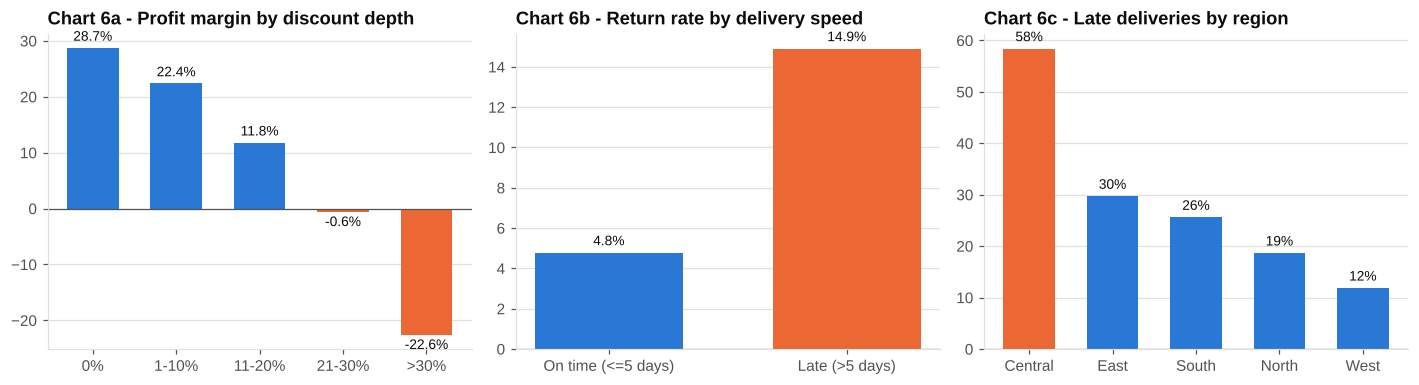

In [11]:
disc = df.groupby("discount_band").agg(orders=("order_id", "count"), revenue=("sales", "sum"), profit=("profit", "sum"),
                                       loss_orders=("is_loss_order", "mean")).assign(margin=lambda x: x.profit / x.revenue * 100)
disc["loss_orders"] *= 100
display(disc)
hi25 = df[(df.order_year == 2025) & (df.discount > 0.20)]
print(f"2025 orders discounted >20%: {len(hi25)} ({len(hi25)/len(df[df.order_year==2025])*100:.1f}% of orders), "
      f"revenue ${hi25.sales.sum():,.0f}, profit ${hi25.profit.sum():,.0f}")
neg = df[df.profit < 0]
print(f"Loss-making orders: {len(neg)} ({len(neg)/len(df)*100:.1f}%), total loss ${neg.profit.sum():,.0f}")

ship = df.groupby("is_late").agg(orders=("order_id", "count"), return_rate=("returned", "mean"))
ship["return_rate"] *= 100
late_by_reg = df.groupby("region").is_late.mean().sort_values(ascending=False) * 100
display(ship); display(late_by_reg)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
bars(axes[0], disc.index.astype(str), disc.margin, colors=[BLUE if v > 0 else ORANGE for v in disc.margin], fmt="{:.1f}%",
     title="Chart 6a - Profit margin by discount depth")
bars(axes[1], ["On time (<=5 days)", "Late (>5 days)"], ship.return_rate.values, colors=[BLUE, ORANGE], fmt="{:.1f}%",
     title="Chart 6b - Return rate by delivery speed")
bars(axes[2], late_by_reg.index, late_by_reg.values, colors=[ORANGE if v > 30 else BLUE for v in late_by_reg.values],
     fmt="{:.0f}%", title="Chart 6c - Late deliveries by region")
plt.tight_layout(); plt.show()

,label,mean_a_%,mean_b_%,test,p_value,verdict
H1,Discount >20% vs <=20% (profit margin),4.87,33.61,Welch t-test + Mann-Whitney U,0.00,Supported (p<0.05)
H2,Marketplace vs other channels (profit margin),9.64,29.63,Welch t-test + Mann-Whitney U,0.00,Supported (p<0.05)
H3,Late vs on-time shipments (return rate),14.91,4.78,Chi-square test of independence,0.00,Supported (p<0.05)


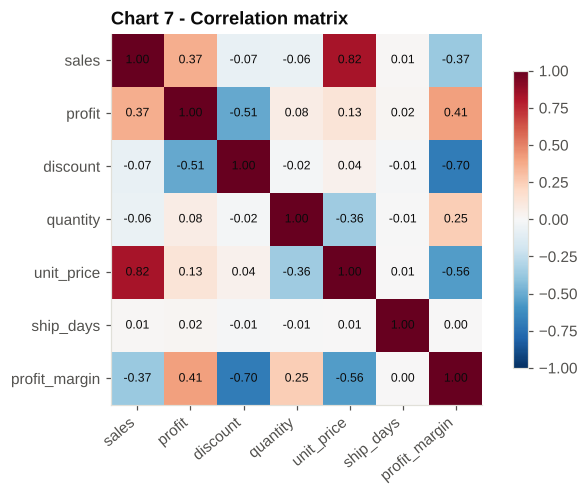

Correlation of discount with profit margin: -0.70


In [12]:
tests = {}
a = df[df.discount > 0.20].profit_margin; b_ = df[df.discount <= 0.20].profit_margin
t = stats.ttest_ind(a, b_, equal_var=False); u = stats.mannwhitneyu(a, b_, alternative="less")
tests["H1"] = {"label": "Discount >20% vs <=20% (profit margin)", "mean_a_%": a.mean() * 100, "mean_b_%": b_.mean() * 100,
               "test": "Welch t-test + Mann-Whitney U", "stat": float(t.statistic), "p_value": float(u.pvalue), "n_a": len(a), "n_b": len(b_)}
a = df[df.channel == "Marketplace"].profit_margin; b_ = df[df.channel != "Marketplace"].profit_margin
t = stats.ttest_ind(a, b_, equal_var=False); u = stats.mannwhitneyu(a, b_, alternative="less")
tests["H2"] = {"label": "Marketplace vs other channels (profit margin)", "mean_a_%": a.mean() * 100, "mean_b_%": b_.mean() * 100,
               "test": "Welch t-test + Mann-Whitney U", "stat": float(t.statistic), "p_value": float(u.pvalue), "n_a": len(a), "n_b": len(b_)}
ct = pd.crosstab(df.is_late, df.returned); chi = stats.chi2_contingency(ct)
tests["H3"] = {"label": "Late vs on-time shipments (return rate)", "mean_a_%": df[df.is_late].returned.mean() * 100,
               "mean_b_%": df[~df.is_late].returned.mean() * 100, "test": "Chi-square test of independence",
               "stat": float(chi[0]), "p_value": float(chi[1]), "n_a": int(df.is_late.sum()), "n_b": int((~df.is_late).sum())}
tdf = pd.DataFrame(tests).T
tdf["verdict"] = np.where(tdf.p_value.astype(float) < 0.05, "Supported (p<0.05)", "Not supported")
display(tdf[["label", "mean_a_%", "mean_b_%", "test", "p_value", "verdict"]])
corr = df[["sales", "profit", "discount", "quantity", "unit_price", "ship_days", "profit_margin"]].corr()
fig, ax = plt.subplots(figsize=(6.4, 4.6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=40, ha="right"); ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center", fontsize=8, color=INK)
ax.set_title("Chart 7 - Correlation matrix", loc="left"); plt.colorbar(im, shrink=0.8); plt.tight_layout(); plt.show()
print("Correlation of discount with profit margin: %.2f" % corr.loc["discount", "profit_margin"])

## 6. Strategic Recommendations - ROI Model
The model works at **order-line level on the 2025 baseline** (the most recent full year) and is applied **sequentially** (1 -> 2 -> 3) so benefits are never double counted. Growth is *not* assumed - benefits are held flat at 2025 volumes.

| # | Recommendation | Mechanism modelled |
|---|---|---|
| 1 | **Discount guardrails** - cap discounts at 20%, approval above | Capped lines are re-priced at 20% off (exact margin recomputed); a share *r1* of those orders is retained, the rest walk away |
| 2 | **Marketplace margin repair** | Marketplace-specific discount cap of 10% (a share *r2* of affected orders retained) plus a renegotiated marketplace fee reduction |
| 3 | **Fulfilment SLA + customer retention** | Late deliveries cut by *x*% (their return rate falls to the on-time rate; recovered profit + 8% avoided handling cost); retention up by *y* pp |

Costs, ramp-up and payback are modelled monthly over 36 months. **All parameters below are assumptions** to be validated in pilots.

In [13]:
CAP = 0.20                                         # company-wide discount cap (Rec 1)
MK_CAP = 0.10                                      # marketplace-specific cap (Rec 2)
HANDLING = 0.08                                    # return handling cost as % of sales (assumption)
b = df[df.order_year == 2025].copy()
b["cogs"] = b.quantity * b.unit_cost
b["list_sales"] = b.quantity * b.unit_price
fee = b.channel_fee.values
pr_late = b[b.is_late].returned.mean(); pr_on = b[~b.is_late].returned.mean()
base_profit_model = (b.sales * (1 - fee) - b.cogs).sum()
print(f"Check - recorded 2025 profit ${b.profit.sum():,.0f} vs rebuilt from components ${base_profit_model:,.0f}")

# customers active in both 2024 and 2025 -> value of one retained customer
both = act[2024] & act[2025]
sales_per_retained = b[b.customer_id.isin(both)].groupby("customer_id").sales.sum().mean()
n_active_2024 = len(act[2024])

SCEN = {
  "Conservative": dict(r1=0.55, r2=0.60, fee_cut=0.00, late_cut=0.25, ret_up=0.03),
  "Base":         dict(r1=0.70, r2=0.70, fee_cut=0.01, late_cut=0.40, ret_up=0.05),
  "Optimistic":   dict(r1=0.80, r2=0.80, fee_cut=0.02, late_cut=0.55, ret_up=0.07)}

def run(p):
    hi = (b.discount > CAP).values
    s_new = b.list_sales.values * (1 - np.where(hi, CAP, b.discount.values))
    p_new = s_new * (1 - fee) - b.cogs.values
    w = np.where(hi, p["r1"], 1.0)
    s1, c1 = w * s_new, w * b.cogs.values
    p1 = s1 * (1 - fee) - c1
    mk = (b.channel == "Marketplace").values
    cap1 = np.minimum(b.discount.values, CAP)
    hit = mk & (cap1 > MK_CAP)
    disc2 = np.where(mk, np.minimum(cap1, MK_CAP), cap1)
    w2 = w * np.where(hit, p["r2"], 1.0)
    fee2 = np.where(mk, fee - p["fee_cut"], fee)
    s2 = w2 * b.list_sales.values * (1 - disc2); c2 = w2 * b.cogs.values
    p2 = s2 * (1 - fee2) - c2
    avoided = (pr_late - pr_on) * p["late_cut"] * b.is_late.values
    ful = (avoided * (np.maximum(p2, 0) + HANDLING * s2)).sum()
    margin_post = p2.sum() / s2.sum()
    ret = p["ret_up"] * n_active_2024 * sales_per_retained * margin_post
    return {"d1": p1.sum() - base_profit_model, "d2": p2.sum() - p1.sum(), "d3": ful + ret, "d3_fulfil": ful, "d3_retention": ret,
            "ds1": s1.sum() - b.sales.sum(), "ds2": s2.sum() - s1.sum(),
            "profit_after": p2.sum() + ful + ret, "sales_after": s2.sum(), "hi_lines": int(hi.sum()),
            "hi_sales": float(b.sales.values[hi].sum()), "hi_profit": float(b.profit.values[hi].sum())}

res = {k: run(v) for k, v in SCEN.items()}
display(pd.DataFrame(res).T[["d1", "d2", "d3", "d3_fulfil", "d3_retention", "profit_after"]])
print(f"2025 baseline profit: ${b.profit.sum():,.0f}  | late return rate {pr_late*100:.1f}% vs on-time {pr_on*100:.1f}%")

Check - recorded 2025 profit $167,088 vs rebuilt from components $167,089


,d1,d2,d3,d3_fulfil,d3_retention,profit_after
Conservative,"57,847.60","10,208.07","10,140.15","2,299.29","7,840.86","245,284.87"
Base,"62,689.59","17,916.25","16,733.30","3,886.79","12,846.51","264,428.19"
Optimistic,"65,917.58","26,376.80","23,450.79","5,598.79","17,852.00","282,834.22"


2025 baseline profit: $167,088  | late return rate 16.4% vs on-time 4.6%


,scenario,item,annual_run_rate,benefit,cost,net,roi,payback
0,Conservative,Rec 1,"57,847.60","159,080.90","21,333.33","137,747.57",645.69,6.00
1,Conservative,Rec 2,"10,208.07","26,370.85","28,000.00","-1,629.15",-5.82,NaN
2,Conservative,Rec 3,"10,140.15","25,350.38","35,250.00","-9,899.62",-28.08,NaN
3,Conservative,total,"78,195.82","210,802.13","84,583.33","126,218.79",149.22,11.00
4,Base,Rec 1,"62,689.59","172,396.37","21,333.33","151,063.04",708.11,6.00
5,Base,Rec 2,"17,916.25","46,283.65","28,000.00","18,283.65",65.30,18.00
6,Base,Rec 3,"16,733.30","41,833.26","35,250.00","6,583.26",18.68,26.00
7,Base,total,"97,339.14","260,513.28","84,583.33","175,929.94",208.00,10.00
8,Optimistic,Rec 1,"65,917.58","181,273.35","21,333.33","159,940.02",749.72,6.00
9,Optimistic,Rec 2,"26,376.80","68,140.06","28,000.00","40,140.06",143.36,13.00


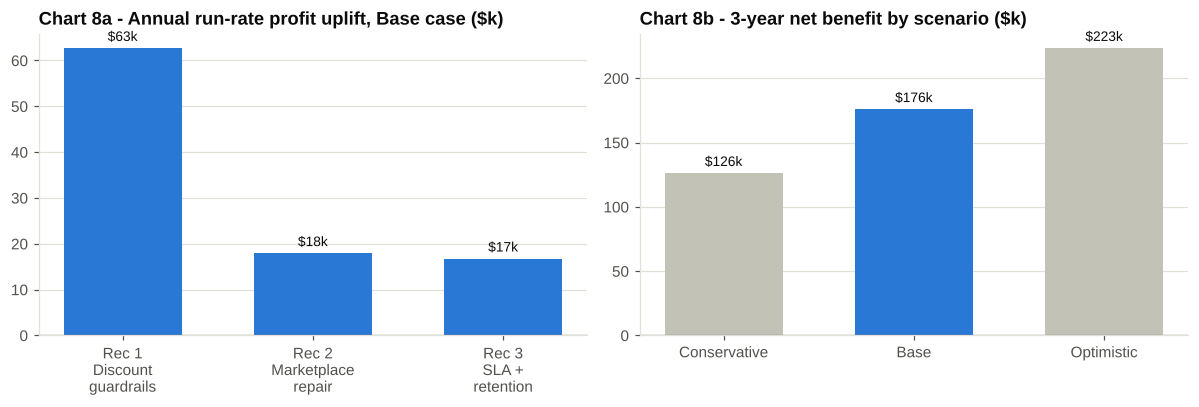

In [14]:
# Monthly cash-flow: costs, go-live, linear 3-month ramp to run-rate, 36-month horizon
COST = {  # (one-time, annual run cost) in USD
  1: (10_000, 4_000), 2: (12_000, 6_000), 3: (12_000, 9_000)}
GO_LIVE = {1: 3, 2: 5, 3: 6}                       # month benefits start to ramp
BUILD = {1: 3, 2: 4, 3: 5}                         # months over which the one-time cost is spent
H = 36

def cashflow(scn):
    out = {}
    net_total = np.zeros(H)
    for i in (1, 2, 3):
        run_rate = res[scn][f"d{i}"] / 12
        ramp = np.clip((np.arange(1, H + 1) - GO_LIVE[i] + 1) / 3, 0, 1)
        ben = run_rate * ramp
        cost = np.zeros(H); cost[:BUILD[i]] = COST[i][0] / BUILD[i]
        cost[GO_LIVE[i] - 1:] += COST[i][1] / 12
        net = ben - cost
        out[i] = dict(benefit=ben.sum(), cost=cost.sum(), net=net.sum(), roi=net.sum() / cost.sum() * 100,
                      payback=int(np.argmax(np.cumsum(net) >= 0) + 1) if (np.cumsum(net) >= 0).any() else None,
                      annual_run_rate=res[scn][f"d{i}"])
        net_total += net
    cum = np.cumsum(net_total)
    ben_t = sum(o["benefit"] for o in out.values()); cost_t = sum(o["cost"] for o in out.values())
    out["total"] = dict(benefit=ben_t, cost=cost_t, net=ben_t - cost_t, roi=(ben_t - cost_t) / cost_t * 100,
                        payback=int(np.argmax(cum >= 0) + 1), annual_run_rate=sum(res[scn][f"d{i}"] for i in (1, 2, 3)),
                        cum=cum.tolist())
    return out

cf = {s: cashflow(s) for s in SCEN}
rows = []
for s in SCEN:
    for k, v in cf[s].items():
        rows.append({"scenario": s, "item": k if k == "total" else f"Rec {k}", **{x: v[x] for x in ["annual_run_rate", "benefit", "cost", "net", "roi", "payback"]}})
roi_df = pd.DataFrame(rows); display(roi_df)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
base = cf["Base"]
bars(axes[0], ["Rec 1\nDiscount\nguardrails", "Rec 2\nMarketplace\nrepair", "Rec 3\nSLA +\nretention"],
     [base[i]["annual_run_rate"] / 1e3 for i in (1, 2, 3)], fmt="${:,.0f}k", title="Chart 8a - Annual run-rate profit uplift, Base case ($k)")
bars(axes[1], list(SCEN), [cf[s]["total"]["net"] / 1e3 for s in SCEN], colors=[GRAY, BLUE, GRAY], fmt="${:,.0f}k",
     title="Chart 8b - 3-year net benefit by scenario ($k)")
plt.tight_layout(); plt.show()

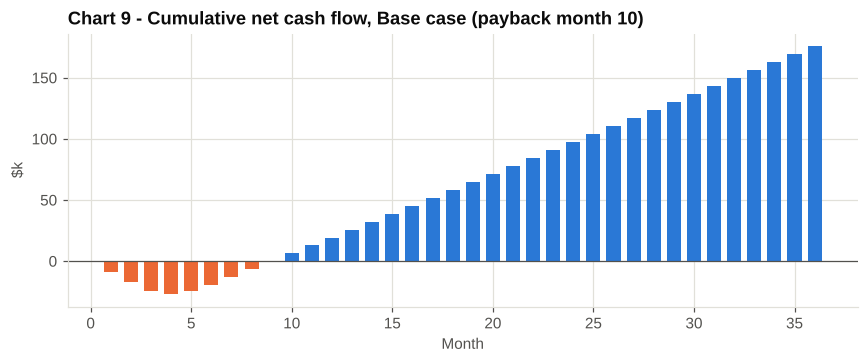

In [15]:
months = np.arange(1, H + 1)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(months, np.array(cf["Base"]["total"]["cum"]) / 1e3, color=[ORANGE if v < 0 else BLUE for v in cf["Base"]["total"]["cum"]], width=0.7)
ax.axhline(0, color=INK2, lw=0.8); ax.set_xlabel("Month"); ax.set_ylabel("$k")
ax.set_title(f"Chart 9 - Cumulative net cash flow, Base case (payback month {cf['Base']['total']['payback']})", loc="left")
plt.tight_layout(); plt.show()

## 7. Implementation Timeline

In [16]:
TIMELINE = [  # (workstream, start month, duration, phase)
  ("Rec 1 - Design discount policy & approval matrix", 1, 2, "Design"),
  ("Rec 1 - Build approval workflow, train sales teams", 2, 1, "Build"),
  ("Rec 1 - Go-live & monthly margin monitoring", 3, 10, "Run"),
  ("Rec 2 - Marketplace fee renegotiation & SKU review", 1, 3, "Design"),
  ("Rec 2 - Price floors / uplift pilot on 2 sub-categories", 4, 2, "Pilot"),
  ("Rec 2 - Full rollout across marketplaces", 6, 7, "Run"),
  ("Rec 3 - Select regional fulfilment partner (Central/East)", 2, 3, "Design"),
  ("Rec 3 - Launch delivery SLA tracking + loyalty tiers", 5, 2, "Build"),
  ("Rec 3 - Scale & optimise (SLA, retention offers)", 7, 6, "Run")]
for t in TIMELINE: print(t)

('Rec 1 - Design discount policy & approval matrix', 1, 2, 'Design')
('Rec 1 - Build approval workflow, train sales teams', 2, 1, 'Build')
('Rec 1 - Go-live & monthly margin monitoring', 3, 10, 'Run')
('Rec 2 - Marketplace fee renegotiation & SKU review', 1, 3, 'Design')
('Rec 2 - Price floors / uplift pilot on 2 sub-categories', 4, 2, 'Pilot')
('Rec 2 - Full rollout across marketplaces', 6, 7, 'Run')
('Rec 3 - Select regional fulfilment partner (Central/East)', 2, 3, 'Design')
('Rec 3 - Launch delivery SLA tracking + loyalty tiers', 5, 2, 'Build')
('Rec 3 - Scale & optimise (SLA, retention offers)', 7, 6, 'Run')


## 8. Export - single source of truth for the deck

In [17]:
def tbl(d): return json.loads(d.reset_index().to_json(orient="records"))
metrics = {
  "log": log, "by_year": json.loads(by_year.reset_index().rename(columns={"index": "metric"}).to_json(orient="records")),
  "category": tbl(cat), "sub": tbl(sub.set_index("sub_category")), "region": tbl(reg), "channel": tbl(chn),
  "channel_mix_pct": json.loads(mix_pct.reset_index().to_json(orient="records")),
  "concentration": conc, "retention": {"2023_24": ret_23_24, "2024_25": ret_24_25, "repeat_share": rep_rate,
                                      "aov_repeat": float(aov_ct["Repeat"]), "aov_onetime": float(aov_ct["One-time"])},
  "discount": tbl(disc), "ship": tbl(ship), "late_by_region": json.loads(late_by_reg.reset_index().to_json(orient="records")),
  "loss_orders": {"n": int(len(neg)), "share_%": len(neg) / len(df) * 100, "total_loss": float(neg.profit.sum())},
  "hi25": {"n": int(len(hi25)), "share_orders_%": len(hi25) / len(df[df.order_year == 2025]) * 100,
           "revenue": float(hi25.sales.sum()), "profit": float(hi25.profit.sum())},
  "tests": tests, "assumptions": {"CAP": CAP, "MK_CAP": MK_CAP, "HANDLING": HANDLING, "SCEN": SCEN, "COST": {str(k): v for k, v in COST.items()},
                                  "GO_LIVE": GO_LIVE, "late_return_rate": pr_late * 100, "ontime_return_rate": pr_on * 100,
                                  "sales_per_retained": sales_per_retained, "n_active_2024": n_active_2024},
  "scenarios": {s: {k: v for k, v in cf[s].items()} for s in SCEN}, "res": res,
  "baseline_2025": {"sales": float(b.sales.sum()), "profit": float(b.profit.sum())},
  "timeline": TIMELINE, "missing_before": missing_before[missing_before > 0].to_dict(),
  "correlation_discount_margin": float(corr.loc["discount", "profit_margin"]),
}
json.dump(metrics, open("metrics.json", "w"), indent=1, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("metrics.json written")

metrics.json written


## 9. Conclusions
* **Growth is real but increasingly unprofitable.** Revenue grew strongly through 2025 while profit margin fell year on year - the growth is being bought with discounts and low-margin marketplace volume.
* **Discounts above 20% destroy value** - the margin turns negative and the relationship is statistically significant (H1).
* **The marketplace channel is the fastest-growing and the least profitable** (H2), and its share of revenue keeps rising.
* **Late deliveries roughly triple return rates** (H3), concentrated in the Central region.
* **Three recommendations** - discount guardrails, marketplace margin repair, fulfilment SLA + retention - are quantified in Section 6 with ROI, payback and a 12-month roadmap. The PDF deck presents them for the C-suite.